# Figure 2 --- the PCA variance spectrum separated by brain state

Produces `figures/fig2_spectra_by_state.png` and two tables:

* **(a)** eigenvalue spectra of Wake, NREM, REM and of the three states pooled into one matrix, with power laws fitted over a stated PC range;
* **(b)** the same exponents refitted over three ranges, which is what decides the ordering of states;
* **(c)** exponent against the number of bins used, the sample-size control.

Every exponent below is defined by four choices, and none of them is optional when quoting it:
**1 s bins**, the **122 retained neurons** (the 15 fastest excluded), the spectrum **normalised to
fraction of total variance**, and an **OLS fit of $\log\lambda_k$ on $\log k$** over the stated range.

In [25]:
# ---------------------------------------------------------------- CONFIG
# Every downstream cell reads these names and none of them redefines them.
import os, sys
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, os.getcwd())

DATA_DIR = "/Users/ilgaz/Desktop/data_share_20260429/data"
# Single source of data for this notebook: the local pack of 1 s binned
# matrices built from the DANDI archive by scripts/crawl_buzsaki.py (stage
# "extract"). The laboratory session files that earlier versions of this
# notebook read --- spike_time_dicts/buzsaki_Achilles_10252013.pkl and
# Achilles_10252013_sessInfo.mat --- are no longer used here; they are kept
# in data/ because the scoring-comparison table still reads them.
FIG_DIR  = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

BIN_SIZE   = 1.0                            # s
STATES     = ["Wake", "NREM", "REM"]
FIT_RANGES = [(1, 20), (1, 50), (3, 50)]    # PC ranges to compare
MAIN_RANGE = (3, 50)                        # the range quoted in the text
N_DRAWS    = 20                             # draws per matched-size estimate
SEED       = 1
COLORS     = {"Wake": "#D55E00", "NREM": "#0072B2", "REM": "#009E73", "pooled": "#555555"}

In [26]:
# -------------------------------------------------- data, epochs, masks
# Source switched to the public archive copy (DANDI 000044) so this session is
# binned and scored exactly as the multi-session set of notebook 06. The
# archive conversion carries three states where the laboratory sessInfo file
# carries five: its waking category absorbs the drowsy and intermediate
# periods and the maze epoch, so Wake here is a broader category (16,747 s
# against the 5,698 s scored Wake by the laboratory). Spike times are
# identical between the two copies; only the state annotation differs.
PACK = DATA_DIR + "/dandi_binned_1s_rat.npz"
TAG  = "000044_sub-Achilles_ses-Achilles-10252013"

_z = np.load(PACK, allow_pickle=True)
X = _z[f"X__{TAG}"].astype(float)               # bins x neurons, 1 s bins
_lab = _z[f"state__{TAG}"].copy()
_lab[_lab == "Quiet"] = "Wake"                  # same mapping as dandi_data.load_pack
neuron_ids    = np.arange(X.shape[1])
sess_duration = X.shape[0] * BIN_SIZE
edges         = np.arange(X.shape[0] + 1) * BIN_SIZE
centres       = edges[:-1] + BIN_SIZE / 2

masks = {s: (_lab == s) for s in STATES}
masks["pooled"] = masks["Wake"] | masks["NREM"] | masks["REM"]

print("session", round(sess_duration, 1), "s |", X.shape[0], "bins x", X.shape[1], "neurons")
print("bins per state:", {k: int(v.sum()) for k, v in masks.items()},
      "| unscored:", int((~np.isin(_lab, STATES)).sum()))


session 34862.0 s | 34862 bins x 137 neurons
bins per state: {'Wake': 16747, 'NREM': 15890, 'REM': 2071, 'pooled': 34708} | unscored: 154


In [27]:
# ------------------------------------- exclude the high-rate minority
# Rule internal to the data: cut at the largest step in the rank-ordered
# log rate. On this session it removes 15 neurons and leaves 122.
rate  = X.sum(0) / sess_duration
order = np.argsort(-np.log(rate))
gap   = -np.diff(np.log(rate)[order])
n_ex  = int(np.argmax(gap[:40])) + 1
keep  = np.setdiff1d(np.arange(X.shape[1]), order[:n_ex])
Xk    = X[:, keep]

assert n_ex == 15 and Xk.shape[1] == 122, (n_ex, Xk.shape)
print("excluded", n_ex, "neurons above", round(float(rate[order[n_ex - 1]]), 2), "Hz ->",
      Xk.shape[1], "retained,", round(100 * X[:, order[:n_ex]].sum() / X.sum(), 1), "% of spikes dropped")

excluded 15 neurons above 4.71 Hz -> 122 retained, 64.8 % of spikes dropped


In [28]:
# ------------------------------------------------- spectrum and fitting
def spectrum(M):
    """Eigenvalue spectrum as a fraction of total variance (columns centred, not z-scored)."""
    M = M - M.mean(0)
    ev = np.linalg.svd(M, compute_uv=False) ** 2
    return ev / ev.sum()

def fit_powerlaw(ev, lo, hi):
    """OLS of log(lambda_k) on log(k) over PCs lo..hi. Returns (alpha, R2, residual rms)."""
    k = np.arange(lo, hi + 1)
    x, y = np.log(k), np.log(ev[lo - 1:hi])
    a, b = np.polyfit(x, y, 1)
    res  = y - (a * x + b)
    return -a, 1 - res.var() / y.var(), float(np.sqrt((res ** 2).mean()))

def daic_power_vs_exp(ev, lo, hi):
    """AIC difference between lambda_k ~ k^-alpha and lambda_k ~ exp(-ck) on the same
    range, both two-parameter fits of log(lambda). Positive favours the power law."""
    k = np.arange(lo, hi + 1)
    y, n = np.log(ev[lo - 1:hi]), hi - lo + 1
    rss = lambda x: ((y - np.polyval(np.polyfit(x, y, 1), x)) ** 2).sum()
    return n * np.log(rss(k) / n) - n * np.log(rss(np.log(k)) / n)

In [29]:
# --------------------------- exponents and goodness of fit, matched size
# All four sets are cut to the size of the smallest state, so the
# sample-size bias shown in panel (c) cannot drive the comparison.
rng       = np.random.default_rng(SEED)
N_MATCHED = min(int(masks[s].sum()) for s in STATES)
sets      = {"pooled": np.where(masks["pooled"])[0], **{s: np.where(masks[s])[0] for s in STATES}}

rows, spec_mean = [], {}
for name, idx in sets.items():
    evs = [spectrum(Xk[rng.choice(idx, N_MATCHED, replace=False)]) for _ in range(N_DRAWS)]
    spec_mean[name] = np.mean(evs, axis=0)
    for lo, hi in FIT_RANGES:
        for ev in evs:
            a, r2, rms = fit_powerlaw(ev, lo, hi)
            rows.append(dict(set=name, range=f"{lo}-{hi}", alpha=a, R2=r2, rms=rms,
                             dAIC=daic_power_vs_exp(ev, lo, hi)))

gof = pd.DataFrame(rows)
table = (gof.groupby(["set", "range"])
            .agg(alpha=("alpha", "mean"), alpha_sd=("alpha", "std"), R2=("R2", "mean"),
                 rms=("rms", "mean"), dAIC=("dAIC", "mean"))
            .round(4).reset_index())
table.to_csv("fig2_gof_table.csv", index=False)

main = f"{MAIN_RANGE[0]}-{MAIN_RANGE[1]}"
print(f"matched to {N_MATCHED} bins, {N_DRAWS} draws, PCs {main}, 1 s bins, 122 neurons\n")
print(table[table.range == main].to_string(index=False))

matched to 2071 bins, 20 draws, PCs 3-50, 1 s bins, 122 neurons

   set range  alpha  alpha_sd     R2    rms     dAIC
  NREM  3-50 0.6317    0.0210 0.9882 0.0482 125.6358
   REM  3-50 0.6221    0.0000 0.9772 0.0675  87.9391
  Wake  3-50 0.8221    0.0161 0.9773 0.0887  25.3434
pooled  3-50 0.7616    0.0158 0.9933 0.0431 120.8198


In [30]:
# ------------------------- full-epoch exponents: the primary analysis
# Every bin each state has. This is the estimate quoted in the text and drawn
# in plots 1-3; the matched-size version computed above is kept as a control.
rows, spec_full = [], {}
for name, idx in sets.items():
    ev = spectrum(Xk[idx])
    spec_full[name] = ev
    a, r2, rms = fit_powerlaw(ev, *MAIN_RANGE)
    rows.append(dict(set=name, bins=len(idx), alpha=a, R2=r2, rms=rms,
                     dAIC=daic_power_vs_exp(ev, *MAIN_RANGE)))

full = pd.DataFrame(rows).round(4).set_index("set")
full.to_csv("fig2_full_epoch.csv")
print(f"full epochs, PCs {main}, 1 s bins, 122 neurons\n")
print(full.to_string())


full epochs, PCs 3-50, 1 s bins, 122 neurons

         bins   alpha      R2     rms      dAIC
set                                            
pooled  34708  0.7498  0.9963  0.0322  150.9884
Wake    16747  0.8086  0.9784  0.0853   27.1489
NREM    15890  0.6258  0.9851  0.0547  117.0167
REM      2071  0.6221  0.9772  0.0675   87.9391


In [31]:
# ------------------------------------------ sample-size control, panel c
ns, rows = np.unique(np.round(np.logspace(np.log10(300), np.log10(15488), 12)).astype(int)), []
for s in STATES:
    idx = np.where(masks[s])[0]
    for n in ns[ns <= len(idx)]:
        a = [fit_powerlaw(spectrum(Xk[rng.choice(idx, n, replace=False)]), *MAIN_RANGE)[0]
             for _ in range(10)]
        rows.append(dict(state=s, n=int(n), alpha=np.mean(a), sd=np.std(a, ddof=1)))

sweep = pd.DataFrame(rows)
sweep.to_csv("fig2_alpha_vs_nbins.csv", index=False)
print(sweep.pivot(index="n", columns="state", values="alpha").round(3).to_string())

state   NREM    REM   Wake
n                         
300    0.721  0.730  0.913
429    0.682  0.694  0.905
615    0.653  0.660  0.858
880    0.655  0.643  0.858
1259   0.648  0.631  0.827
1802   0.636  0.622  0.832
2579   0.642    NaN  0.818
3691   0.630    NaN  0.811
5283   0.629    NaN  0.816
7561   0.633    NaN  0.806
10821  0.625    NaN  0.808
15488  0.626    NaN  0.809


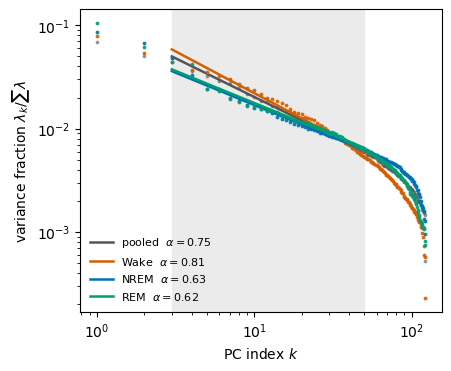

In [32]:
# ------------------------------------- plot 1: the spectrum, separated
# Full epochs: each state's own data, which is what the text reports.
lo, hi = MAIN_RANGE
kk = np.arange(1, Xk.shape[1] + 1)
fig, ax = plt.subplots(figsize=(4.4, 3.6), constrained_layout=True)

for name in ["pooled"] + STATES:
    ev = spec_full[name]
    ax.loglog(kk, ev, ".", ms=3.5, color=COLORS[name], alpha=0.5 if name == "pooled" else 0.85)
    a, b = np.polyfit(np.log(kk[lo - 1:hi]), np.log(ev[lo - 1:hi]), 1)
    ax.loglog(kk[lo - 1:hi], np.exp(b) * kk[lo - 1:hi] ** a, "-", lw=1.8, color=COLORS[name],
              label=f"{name}  $\\alpha = {-a:.2f}$")
ax.axvspan(lo, hi, color="0.92", zorder=0)
ax.set_xlabel("PC index $k$")
ax.set_ylabel("eigenvalue $\\lambda_k$  (fraction of total variance)")
ax.legend(frameon=False, fontsize=8, loc="lower left")
fig.savefig(os.path.join(FIG_DIR, "fig2a_spectra_by_state.png"), dpi=300)


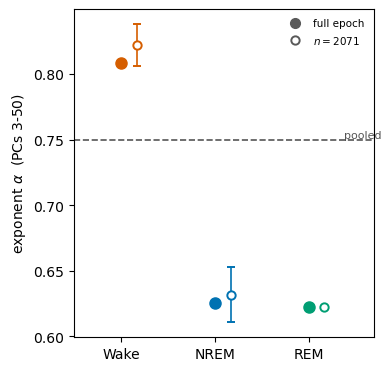

In [33]:
# ------------------------------------------- plot 2: states vs slope
# Filled marker: full epoch (primary). Open marker: matched n, mean +- s.d.
# over N_DRAWS draws, offset in x so the control is visible beside its value.
main_rows = table[table.range == main].set_index("set")
fig, ax = plt.subplots(figsize=(3.8, 3.6), constrained_layout=True)

x = np.arange(len(STATES))
for i, s in enumerate(STATES):
    ax.plot(i, full.alpha[s], "o", ms=8, color=COLORS[s])
    # value label on the full-epoch marker only: that is the reported number,
    # and labelling the control as well would crowd the axes. Three decimals
    # because the two sleep states differ in the third.
    ax.annotate(f"{full.alpha[s]:.3f}", (i, full.alpha[s]), textcoords="offset points",
                xytext=(-13, -3), ha="right", fontsize=7.5, color=COLORS[s])
    ax.errorbar(i + 0.17, main_rows.alpha[s], yerr=main_rows.alpha_sd[s], fmt="o", ms=6,
                mfc="white", mew=1.4, elinewidth=1.2, capsize=3, color=COLORS[s])
ax.axhline(full.alpha["pooled"], color=COLORS["pooled"], ls="--", lw=1.2)
ax.text(len(STATES) - 0.62, full.alpha["pooled"], "pooled", va="bottom", fontsize=8,
        color=COLORS["pooled"])
ax.plot([], [], "o", ms=7, color="0.35", label="full epoch")
ax.plot([], [], "o", ms=6, mfc="white", mew=1.4, color="0.35", label=f"$n = {N_MATCHED}$")
ax.legend(frameon=False, fontsize=7.5, loc="upper right")
ax.set_xticks(x)
ax.set_xticklabels(STATES)
ax.set_xlim(-0.78, len(STATES) - 0.3)   # room for the value label on Wake
ax.set_ylabel(f"exponent $\\alpha$  (PCs {main})")
fig.savefig(os.path.join(FIG_DIR, "fig2b_slope_by_state.png"), dpi=300)


## (d) Does the spectrum actually follow a power law?

Panels (a)-(b) measure *how fast* the spectrum decays and how well a line
describes it. Neither answers whether "power law" is the right functional form:
$R^2$ is near $1$ for any monotonically decaying spectrum on log-log axes, so
the values above cannot discriminate a power law from a log-normal or an
exponentially truncated one.

This section tests the form, following Clauset et al. (2009), and leaves the
reported exponents untouched -- the OLS estimates over PCs 3-50 above remain the
numbers quoted in the text. Three steps:

1. **Cutoff and exponent, found together.** The smallest eigenvalues are
   sampling noise, so a power law can only be claimed above some
   $\lambda_{min}$, and a KS distance cannot be computed without a fitted curve
   to measure it against. The two are therefore found in one scan: every
   observed eigenvalue is tried as a candidate cutoff, the exponent is fitted by
   maximum likelihood on the eigenvalues above it, and the KS distance to that
   fitted distribution is recorded. The pair with the smallest distance is kept
   -- one cutoff and the one $\hat\alpha$ belonging to it. On the NREM spectrum
   the scan runs over 112 candidates and $\hat\alpha$ varies from $1.53$ (all
   $122$ eigenvalues) to $2.72$ across them, so the cutoff choice is not a
   detail of presentation.
2. **Absolute fit.** $D$ alone has no scale, so it is calibrated by simulation:
   500 synthetic datasets are drawn from the *fitted* power law, each refitted
   from scratch including cutoff selection, and $p$ is the fraction whose $D$
   exceeds the observed one. A high $p$ means the data deviate no more than
   genuine power-law samples of the same size do -- it is compatibility, not
   proof.
3. **Alternatives.** Log-normal, stretched exponential, exponential and
   truncated power law are fitted to the same tail and compared by normalised
   likelihood ratio (Vuong). This is the step that carries information, because
   a short tail cannot discriminate much.

Estimators live in `../scripts/powerlaw_gof.py`; `selftest()` there recovers
known Pareto exponents and the $\alpha = 1 + 1/a$ identity on synthetic spectra.


In [34]:
# ------------------------------------- (d) power-law goodness of fit
# Runs on spec_full, the same full-epoch spectra drawn in plots 1-3, so the
# test and the reported exponents describe one and the same measurement.
#
# Everything here comes from the `powerlaw` package (Alstott, Bullmore & Plenz
# 2014), the reference implementation of the Clauset, Shalizi & Newman (2009)
# procedure: pip install powerlaw. Fit() scans every candidate cutoff, fits the
# exponent by maximum likelihood above it and keeps the cutoff with the
# smallest Kolmogorov-Smirnov distance. distribution_compare() returns Vuong's
# normalised log-likelihood ratio R (positive favours the power law) and its
# two-sided p-value.
import warnings
import powerlaw
warnings.filterwarnings("ignore")

GOF_REPS = 500                      # bootstrap replicates per state
rng_gof  = np.random.default_rng(SEED)

ALTS = ["lognormal", "exponential", "truncated_power_law", "stretched_exponential"]


def bootstrap_p(ev, fit, reps, rng):
    """Clauset's semi-parametric bootstrap p-value.

    The package reports D but no p-value, so we build the reference ourselves:
    each replicate draws a fresh Pareto tail above the fitted cutoff and
    resamples the body below it, then is refitted FROM SCRATCH, cutoff search
    included, so the observed D is compared with distances that enjoyed the
    same optimisation.
    """
    pl = fit.power_law
    xmin, alpha, d_obs = pl.xmin, pl.alpha, pl.D
    body = np.asarray(ev)[np.asarray(ev) < xmin]
    n, frac = len(ev), pl.n / len(ev)
    worse = 0
    for _ in range(reps):
        k = int((rng.random(n) < frac).sum())
        tail = xmin * (1.0 - rng.random(k)) ** (-1.0 / (alpha - 1.0))
        rest = rng.choice(body, n - k, replace=True) if len(body) else np.array([])
        d_syn = powerlaw.Fit(np.concatenate([tail, rest]), discrete=False,
                             verbose=False).power_law.D
        worse += d_syn >= d_obs
    return worse / reps


rows = []
for name in STATES + ["pooled"]:
    ev = spec_full[name]
    f = powerlaw.Fit(ev, discrete=False, verbose=False)
    pl = f.power_law
    rec = dict(set=name, n_eig=len(ev), n_tail=pl.n, xmin=pl.xmin,
               alpha_mle=pl.alpha, alpha_se=pl.sigma, ks_D=pl.D,
               p_boot=bootstrap_p(ev, f, GOF_REPS, rng_gof),
               a_ols=full.alpha[name], R2_ols=full.R2[name])
    for alt in ALTS:
        rec[f"R_{alt}"], rec[f"p_{alt}"] = f.distribution_compare(
            "power_law", alt, normalized_ratio=True)
    rows.append(rec)

gof_pl = pd.DataFrame(rows).set_index("set").round(4)
gof_pl.to_csv("fig2d_gof_powerlaw.csv")

print(f"powerlaw {powerlaw.__version__}, full epochs, 122 neurons, "
      f"{GOF_REPS} bootstrap replicates\n")
print(gof_pl[["n_tail", "xmin", "alpha_mle", "alpha_se", "ks_D", "p_boot",
              "a_ols", "R2_ols"]].to_string())
print("\nmodel comparison, R > 0 favours the power law:")
print(gof_pl[[c for c in gof_pl.columns if c.startswith(("R_", "p_"))
              and c != "p_boot"]].to_string())


Assuming nested distributions
'nan' in fit cumulative distribution values.
Likely underflow or overflow error: the optimal fit for this distribution gives values that are so extreme that we lack the numerical precision to calculate them.
Assuming nested distributions
'nan' in fit cumulative distribution values.
Likely underflow or overflow error: the optimal fit for this distribution gives values that are so extreme that we lack the numerical precision to calculate them.
Assuming nested distributions


powerlaw 1.4.4, full epochs, 122 neurons, 500 bootstrap replicates

        n_tail    xmin  alpha_mle  alpha_se    ks_D  p_boot   a_ols  R2_ols
set                                                                        
Wake        67  0.0038     2.0778    0.1317  0.0741   0.184  0.8086  0.9784
NREM        50  0.0064     2.7631    0.2493  0.0311   0.998  0.6258  0.9851
REM         36  0.0082     2.7646    0.2941  0.0548   0.856  0.6221  0.9772
pooled      58  0.0053     2.3850    0.1819  0.0564   0.634  0.7498  0.9963

model comparison, R > 0 favours the power law:
        R_lognormal  p_lognormal  R_exponential  p_exponential  R_truncated_power_law  p_truncated_power_law  R_stretched_exponential  p_stretched_exponential
set                                                                                                                                                           
Wake        -1.3824       0.1669         0.5692         0.5692                -1.6907                 0.0159  

Assuming nested distributions


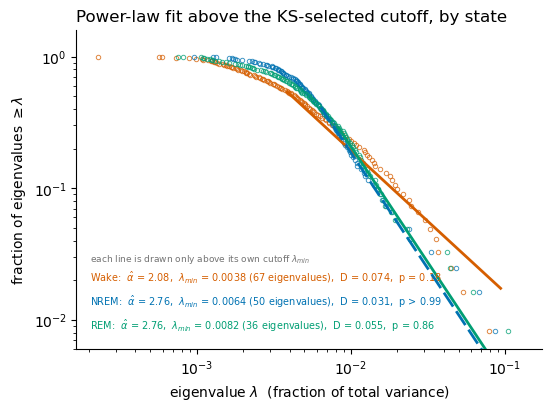

In [35]:
# ------------------------------ plot 3: goodness of fit above the KS cutoff
# One panel: empirical CCDF per state, the maximum-likelihood power law drawn
# only over the range it was fitted on, and the three diagnostics.
fig, ax = plt.subplots(figsize=(5.4, 4.0), constrained_layout=True)

# All three fits are solid. NREM and REM have nearly the same exponent but
# different cutoffs, so their lines start at different points and remain
# distinguishable; NREM is drawn last so it is not hidden where they cross.

for s in STATES:
    ev = np.sort(spec_full[s])[::-1]
    n  = len(ev)
    ax.loglog(ev, np.arange(1, n + 1) / n, ls="none", marker="o", ms=3.2,
              mfc="none", mew=.7, color=COLORS[s], alpha=.75)
    xmin, alpha, n_tail = gof_pl.xmin[s], gof_pl.alpha_mle[s], gof_pl.n_tail[s]
    fx = np.geomspace(xmin, ev[0] * 1.2, 100)
    ax.loglog(fx, (n_tail / n) * (fx / xmin) ** (1 - alpha), color=COLORS[s], lw=2,
              zorder=4 if s == "NREM" else 3)

ax.text(0.03, 0.275, "each line is drawn only above its own cutoff $\\lambda_{min}$",
        transform=ax.transAxes, fontsize=6.5, color="0.45")
for i, s in enumerate(STATES):
    # a bootstrap p of exactly 1 is impossible with 500 replicates, so the
    # top of the range is written as an inequality rather than rounded to 1.00
    p = gof_pl.p_boot[s]
    p_txt = "> 0.99" if p > 0.99 else f"= {p:.2f}"
    ax.text(0.02, 0.20 - i * 0.075,
            f"{s}:  $\\hat{{\\alpha}}$ = {gof_pl.alpha_mle[s]:.2f},"
            f"  $\\lambda_{{min}}$ = {gof_pl.xmin[s]:.4f} ({int(gof_pl.n_tail[s])} eigenvalues),"
            f"  D = {gof_pl.ks_D[s]:.3f},  p {p_txt}",
            transform=ax.transAxes, fontsize=6.4, color=COLORS[s], va="bottom")

ax.set_xlabel("eigenvalue $\\lambda$  (fraction of total variance)")
ax.set_ylabel("fraction of eigenvalues $\\geq \\lambda$")
ax.set_title("Power-law fit above the KS-selected cutoff, by state", loc="left")
ax.set_ylim(6e-3, 1.6)
ax.spines[["top", "right"]].set_visible(False)
fig.savefig(os.path.join(FIG_DIR, "fig2c_goodness_of_fit.png"), dpi=300)


In [36]:
# ----------------------- control: is the Wake result just fewer bins?
# Wake has 5,698 bins against NREM's 15,488, so the state difference in (d)
# is re-tested with every state cut to REM's bin count. Same package calls.
rng_m = np.random.default_rng(SEED)
rows  = []
for s in STATES:
    idx = np.where(masks[s])[0]
    for d in range(1 if s == "REM" else 10):
        ev = spectrum(Xk[idx if s == "REM" else rng_m.choice(idx, N_MATCHED, replace=False)])
        f = powerlaw.Fit(ev, discrete=False, verbose=False)
        rec = dict(state=s, draw=d, alpha=f.power_law.alpha, ks_D=f.power_law.D,
                   n_tail=f.power_law.n, a_ols=fit_powerlaw(ev, *MAIN_RANGE)[0])
        for alt in ("lognormal", "truncated_power_law"):
            rec[f"R_{alt}"], rec[f"p_{alt}"] = f.distribution_compare(
                "power_law", alt, normalized_ratio=True)
        rows.append(rec)

gof_m = pd.DataFrame(rows)
gof_m.to_csv("fig2d_gof_matched.csv", index=False)

print(f"matched to REM's {N_MATCHED} bins, 10 draws per state\n")
print(gof_m.groupby("state")[["alpha", "ks_D", "n_tail", "a_ols"]].median().round(3).to_string())
print("\nfraction of draws in which a truncated power law fits better (p < 0.10):")
print(gof_m.assign(tr=(gof_m.R_truncated_power_law < 0) & (gof_m.p_truncated_power_law < .10))
           .groupby("state").tr.mean().round(2).to_string())
print("\nfraction in which the power law beats the log-normal (p < 0.05):")
print(gof_m.assign(pl=(gof_m.R_lognormal > 0) & (gof_m.p_lognormal < .05))
           .groupby("state").pl.mean().round(2).to_string())


Assuming nested distributions
Assuming nested distributions
Assuming nested distributions
Assuming nested distributions
Assuming nested distributions
Assuming nested distributions
Assuming nested distributions
Assuming nested distributions
Assuming nested distributions
Assuming nested distributions
'nan' in fit cumulative distribution values.
Likely underflow or overflow error: the optimal fit for this distribution gives values that are so extreme that we lack the numerical precision to calculate them.
Assuming nested distributions
'nan' in fit cumulative distribution values.
Likely underflow or overflow error: the optimal fit for this distribution gives values that are so extreme that we lack the numerical precision to calculate them.
Assuming nested distributions
Assuming nested distributions
'nan' in fit cumulative distribution values.
Likely underflow or overflow error: the optimal fit for this distribution gives values that are so extreme that we lack the numerical precision to ca

matched to REM's 2071 bins, 10 draws per state

       alpha   ks_D  n_tail  a_ols
state                             
NREM   2.704  0.034    44.5  0.632
REM    2.765  0.055    36.0  0.622
Wake   2.030  0.084    67.5  0.819

fraction of draws in which a truncated power law fits better (p < 0.10):
state
NREM    0.0
REM     0.0
Wake    0.9

fraction in which the power law beats the log-normal (p < 0.05):
state
NREM    0.0
REM     0.0
Wake    0.0


'nan' in fit cumulative distribution values.
Likely underflow or overflow error: the optimal fit for this distribution gives values that are so extreme that we lack the numerical precision to calculate them.
Assuming nested distributions


In [ ]:
# --------------------------------- (d) the same exponent, by maximum likelihood
# Panel 2B reports alpha from the least-squares fit over PCs 3-50. Here the
# maximum-likelihood tail index alpha-hat of panel (c) is converted into the
# same units by alpha = 1 / (alpha-hat - 1), so the two panels can be read
# against each other. The standard error is propagated through that identity,
# |d alpha / d alpha-hat| = 1 / (alpha-hat - 1)^2, from the package's own
# sigma. The two estimates are not expected to coincide: they are fitted over
# different ranges, the likelihood fit including the leading components that
# the least-squares fit excludes.
# Styling follows plot 2 so the two panels read as a pair: same figure size,
# same marker size and colours, same dashed pooled line and label placement.
a_conv = 1.0 / (gof_pl.alpha_mle - 1.0)
se_conv = gof_pl.alpha_se / (gof_pl.alpha_mle - 1.0) ** 2

fig, ax = plt.subplots(figsize=(3.8, 3.6), constrained_layout=True)
x = np.arange(len(STATES))
for i, s in enumerate(STATES):
    ax.errorbar(i, a_conv[s], yerr=se_conv[s], fmt="o", ms=8, color=COLORS[s],
                elinewidth=1.2, capsize=3)
    ax.annotate(f"{a_conv[s]:.3f}", (i, a_conv[s]), textcoords="offset points",
                xytext=(-13, -3), ha="right", fontsize=7.5, color=COLORS[s])
ax.axhline(a_conv["pooled"], color=COLORS["pooled"], ls="--", lw=1.2)
ax.text(len(STATES) - 0.62, a_conv["pooled"], "pooled", va="bottom", fontsize=8,
        color=COLORS["pooled"])
ax.set_xticks(x)
ax.set_xticklabels(STATES)
ax.set_xlim(-0.78, len(STATES) - 0.3)   # room for the value label on Wake
ax.set_ylabel(r"exponent $\alpha$  (from $\hat{\alpha}$)")
fig.savefig(os.path.join(FIG_DIR, "fig2d_alpha_converted.png"), dpi=300)

tbl_d = pd.DataFrame(dict(alpha_mle=gof_pl.alpha_mle, alpha_se=gof_pl.alpha_se,
                          alpha_converted=a_conv, se_converted=se_conv,
                          alpha_ols_3_50=full.alpha.reindex(gof_pl.index)))
tbl_d.round(4).to_csv("fig2d_alpha_converted.csv")
print(tbl_d.round(3).to_string())


## The three figures

* `fig2a_spectra_by_state.png` --- the spectrum separated by state, power laws
  fitted over PCs 3--50 (the shaded band marks the fitted range).
* `fig2b_slope_by_state.png` --- exponent by state, full epoch as filled
  markers, the equal-size control as open markers, pooled value dashed.
* `fig2c_goodness_of_fit.png` --- the maximum-likelihood power law drawn above
  the KS-selected cutoff, with the KS distance and bootstrap $p$ per state.

Tables written alongside: `fig2_gof_table.csv` (exponents over three ranges,
matched size), `fig2_full_epoch.csv` (the primary exponents),
`fig2_alpha_vs_nbins.csv` (the sample-size control, computed and quoted in the
text but no longer plotted), `fig2d_gof_powerlaw.csv` and
`fig2d_gof_matched.csv` (the likelihood diagnostics and the bin-matched
control).

The two control *plots* --- exponent against fitting range, and against number
of bins --- were dropped from the figure on request; both controls are still
computed above and quoted in the text.
